# Imports y configuracion 


In [ ]:
import os
import numpy as np
import cv2 as cv
import mediapipe as mp
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from mediapipe.tasks import python
from mediapipe.tasks.python import vision


BASE_DIR = os.getcwd()
MODEL_DIR = os.path.abspath(os.path.join(BASE_DIR, '..', 'models', 'hand_landmarker.task'))
DATASET_DIR = os.path.abspath(os.path.join(BASE_DIR, '..', 'data', 'Senas de LSCh.v5i.tensorflow'))

BaseOptions = python.BaseOptions
HandLandmarker = vision.HandLandmarker
HandLandmarkerOptions = vision.HandLandmarkerOptions
VisionRunningMode = vision.RunningMode

# Grafo de conexiones (reutilizado de main.py)
HAND_CONNECTIONS = [
    (0, 1), (1, 2), (2, 3), (3, 4),          # pulgar
    (0, 5), (5, 6), (6, 7), (7, 8),          # indice
    (5, 9), (9, 10), (10, 11), (11, 12),     # medio
    (9, 13), (13, 14), (14, 15), (15, 16),   # anular
    (13, 17), (17, 18), (18, 19), (19, 20),  # menique
    (0, 17),                                 # palma
]

# Excluimos letras que requieren movimiento (J, Z)
LETRAS_EXCLUIDAS = {'J', 'Z'}
LABELS = [letra for letra in 'ABCDEFGHIJKLMNOPQRSTUVWXYZ' if letra not in LETRAS_EXCLUIDAS]

LANDMARK_NAMES = [
    'muneca',
    'pulgar_cmc', 'pulgar_mcp', 'pulgar_ip', 'pulgar_tip',
    'indice_mcp', 'indice_pip', 'indice_dip', 'indice_tip',
    'medio_mcp', 'medio_pip', 'medio_dip', 'medio_tip',
    'anular_mcp', 'anular_pip', 'anular_dip', 'anular_tip',
    'menique_mcp', 'menique_pip', 'menique_dip', 'menique_tip',
]

def get_hand_data(result):
    """Extrae los datos posicionales del grafo de la mano detectada."""
    hands = []
    if result is None or not result.hand_landmarks:
        return hands
    for hand in result.hand_landmarks:
        coords = np.array([[lm.x, lm.y, lm.z] for lm in hand], dtype=np.float32)
        hands.append({'coords': coords})
    return hands

def draw_hand_graph(frame, hands):
    """Dibuja los landmarks (nodos) y conexiones (aristas) de cada mano detectada."""
    h, w = frame.shape[:2]
    for hand in hands:
        pts = [(int(x * w), int(y * h)) for x, y, _ in hand['coords']]
        for a, b in HAND_CONNECTIONS:
            cv.line(frame, pts[a], pts[b], (0, 255, 0), 2)
        for idx, p in enumerate(pts):
            cv.circle(frame, p, 4, (0, 0, 255), -1)
            cv.putText(frame, str(idx), (p[0] + 5, p[1] - 5),
                       cv.FONT_HERSHEY_SIMPLEX, 0.35, (255, 255, 255), 1)
    return frame




def detectar_mano_imagen(frame, row, landmarker):
    """Intenta detectar la mano en la imagen completa; si falla, recorta usando el bounding box del CSV."""
    frame2RGB = cv.cvtColor(frame, cv.COLOR_BGR2RGB)
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame2RGB)
    result = landmarker.detect(mp_image)
    hands = get_hand_data(result)
    if hands:
        return hands, frame

    h, w = frame.shape[:2]
    margin = 60
    x1 = max(0, int(row['xmin']) - margin)
    y1 = max(0, int(row['ymin']) - margin)
    x2 = min(w, int(row['xmax']) + margin)
    y2 = min(h, int(row['ymax']) + margin)
    crop = frame[y1:y2, x1:x2].copy()
    crop_rgb = cv.cvtColor(crop, cv.COLOR_BGR2RGB)
    result = landmarker.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=crop_rgb))
    hands = get_hand_data(result)
    return hands, crop


options = HandLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=MODEL_DIR),
    running_mode=VisionRunningMode.IMAGE,
    num_hands=1,
    min_hand_detection_confidence=0.35,
    min_hand_presence_confidence=0.30,
    min_tracking_confidence=0.30,
)


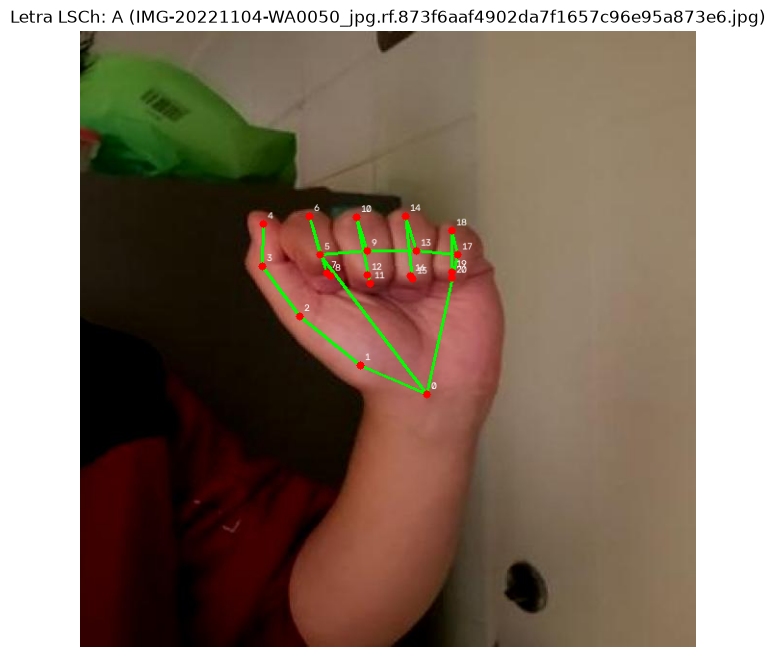

(array([ 0.        ,  0.        ,  0.        , -0.37302807, -0.163442  ,
       -0.17136793, -0.7132688 , -0.43936566, -0.2543095 , -0.9237768 ,
       -0.7195793 , -0.3252782 , -0.91886276, -0.955325  , -0.34448683,
       -0.5972462 , -0.7813485 , -0.12452239, -0.66060776, -0.9971245 ,
       -0.29567698, -0.5597032 , -0.68080884, -0.32913497, -0.5393112 ,
       -0.6618453 , -0.3367886 , -0.3353731 , -0.80699635, -0.09904861,
       -0.39487815, -0.99374306, -0.27369362, -0.31745085, -0.61885697,
       -0.25406158, -0.33362114, -0.67029524, -0.21449257, -0.05895783,
       -0.80521566, -0.10568088, -0.12000611, -1.        , -0.27637672,
       -0.08304719, -0.64979255, -0.15928411, -0.09272982, -0.66565555,
       -0.05251855,  0.17150411, -0.7806152 , -0.12824391,  0.14181133,
       -0.91886985, -0.20539632,  0.13710473, -0.68492687, -0.11824042,
        0.13831525, -0.6545679 , -0.03959389], dtype=float32), 'A')


In [2]:

def normalizacion_etiquetado(hands, label):
    if not hands:
        return None, None
    coords = hands[0]['coords']
    coords = coords - coords[0]
    absmax = np.max(np.abs(coords))
    norm_coords = (coords / absmax).flatten()
    return norm_coords, label
# Prueba visual con una imagen del dataset chileno (LSCh) leyendo _annotations.csv
train_csv = os.path.join(DATASET_DIR, 'train', '_annotations.csv')
df_train_ann = pd.read_csv(train_csv)

sample_row = df_train_ann.iloc[0]
img_path = os.path.join(DATASET_DIR, 'train', sample_row['filename'])
label_muestra = str(sample_row['class']).upper()
frame = cv.imread(img_path)

with HandLandmarker.create_from_options(options) as landmarker:
    hands, frame_usado = detectar_mano_imagen(frame.copy(), sample_row, landmarker)

draw_hand_graph(frame_usado, hands)

plt.figure(figsize=(8, 8))
plt.title(f"Letra LSCh: {label_muestra} ({sample_row['filename']})")
plt.imshow(cv.cvtColor(frame_usado, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

print(normalizacion_etiquetado(hands, label_muestra))

# Extraccion de coordenadas y creacion del CSV (Letras estaticas LSCh)


In [3]:
# Nombres de las 63 columnas de coordenadas: muneca_x, muneca_y, muneca_z, ..., menique_tip_z
COORD_COLS = [f'{nombre}_{eje}' for nombre in LANDMARK_NAMES for eje in ('x', 'y', 'z')]

def procesar_dataset_lsch(splits=('train', 'valid', 'test')):
    filas = []
    with HandLandmarker.create_from_options(options) as landmarker:
        for split in splits:
            split_dir = os.path.join(DATASET_DIR, split)
            csv_path = os.path.join(split_dir, '_annotations.csv')
            if not os.path.exists(csv_path):
                continue

            df_ann = pd.read_csv(csv_path)
            detectadas = 0
            total_estaticas = 0

            for _, row in df_ann.iterrows():
                label = str(row['class']).strip().upper()
                if label in LETRAS_EXCLUIDAS:
                    continue

                total_estaticas += 1
                img_path = os.path.join(split_dir, row['filename'])
                frame = cv.imread(img_path)
                if frame is None:
                    continue

                hands, _ = detectar_mano_imagen(frame, row, landmarker)
                norm_coords, lbl = normalizacion_etiquetado(hands, label)
                if norm_coords is not None:
                    detectadas += 1
                    registro = {col: val for col, val in zip(COORD_COLS, norm_coords)}
                    registro['label'] = lbl
                    registro['split'] = split
                    filas.append(registro)

            print(f"[{split}] Manos detectadas: {detectadas}/{total_estaticas} ({detectadas/max(1, total_estaticas)*100:.1f}%)")

    return pd.DataFrame(filas)

df_coordenadas = procesar_dataset_lsch()
OUTPUT_CSV = os.path.abspath(os.path.join(BASE_DIR, '..', 'data', 'lsch_coordenadas_estaticas.csv'))
df_coordenadas.to_csv(OUTPUT_CSV, index=False)
print(f"\nCSV guardado en: {OUTPUT_CSV} con {len(df_coordenadas)} muestras.")
df_coordenadas.head()

[train] Manos detectadas: 2009/2199 (91.4%)
[valid] Manos detectadas: 203/212 (95.8%)
[test] Manos detectadas: 105/109 (96.3%)

CSV guardado en: c:\Users\basti\Desktop\PDI\proyecto-PDI\data\lsch_coordenadas_estaticas.csv con 2317 muestras.


,muneca_x,muneca_y,muneca_z,pulgar_cmc_x,pulgar_cmc_y,pulgar_cmc_z,pulgar_mcp_x,pulgar_mcp_y,pulgar_mcp_z,pulgar_ip_x,...,menique_pip_y,menique_pip_z,menique_dip_x,menique_dip_y,menique_dip_z,menique_tip_x,menique_tip_y,menique_tip_z,label,split
0,0.0,0.0,0.0,-0.373028,-0.163442,-0.171368,-0.713269,-0.439366,-0.254310,-0.923777,...,-0.918870,-0.205396,0.137105,-0.684927,-0.118240,0.138315,-0.654568,-0.039594,A,train
1,0.0,0.0,0.0,-0.111628,0.250593,0.180930,-0.071791,0.422926,0.264320,0.030348,...,0.469022,0.219414,0.406075,0.448553,0.332661,0.359935,0.406820,0.413362,N,train
2,0.0,0.0,0.0,-0.183837,0.169053,0.025842,-0.181448,0.362759,0.047203,-0.070292,...,0.483592,0.057922,0.207575,0.452157,0.085035,0.172982,0.404512,0.107834,N,train
3,0.0,0.0,0.0,-0.207766,-0.094768,-0.101700,-0.370894,-0.243559,-0.144500,-0.425906,...,-0.660195,0.000973,-0.006568,-0.752979,-0.017277,-0.033765,-0.839190,-0.034530,B,train
4,0.0,0.0,0.0,-0.184779,-0.027036,-0.092117,-0.360960,-0.171185,-0.146899,-0.425695,...,-0.620895,-0.171417,0.084036,-0.726143,-0.196425,0.064836,-0.819447,-0.212965,B,train
